In [58]:
# pip install ta_lib

In [59]:
import pandas as pd
import numpy as np
import yfinance as yf
import talib
df = yf.download('GC=F', start='2020-01-01', end='2025-01-01')
df = df.droplevel('Ticker', axis=1)
df


/tmp/ipython-input-2345980050.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('GC=F', start='2020-01-01', end='2025-01-01')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,1524.500000,1528.699951,1518.000000,1518.099976,214
2020-01-03,1549.199951,1552.699951,1530.099976,1530.099976,107
2020-01-06,1566.199951,1580.000000,1560.400024,1580.000000,416
2020-01-07,1571.800049,1576.300049,1558.300049,1558.300049,47
2020-01-08,1557.400024,1604.199951,1552.300049,1579.699951,236
...,...,...,...,...,...
2024-12-24,2620.000000,2620.000000,2609.500000,2613.000000,35
2024-12-26,2638.800049,2638.800049,2627.899902,2628.500000,84
2024-12-27,2617.199951,2617.699951,2616.399902,2617.699951,642


In [60]:
import pandas as pd
import numpy as np


def label_market_regime(df, window_size=10, range_threshold=0.02):
    """
    Labels market regimes based on the range of a 5-period moving average (MA5) in a rolling window.

    Parameters:
    - df: pd.DataFrame with 'Close' column, indexed by date or bar number.
    - window_size: Size of the rolling window to compute MA5 range.
    - range_threshold: Threshold for MA5 range (in price units) to label as 'sideways'.

    Returns:
    - pd.Series with regime labels ('sideways', 'trending', or 'unknown').
    """
    # Compute 5-period moving average
    df['ma5'] = df['Close'].rolling(window=2).mean()

    # Calculate MA5 range (max MA5 - min MA5) in the rolling window
    ma5_range = df['ma5'].rolling(window=window_size, min_periods=1).apply(lambda x: (np.max(x) - np.min(x))/np.min(x))

    # Label regimes based on MA5 range
    regimes = pd.Series('unknown', index=df.index)
    regimes = np.where(ma5_range < range_threshold, 'sideways', 'trending')

    # Ensure NaNs in ma5_range (due to insufficient window size) result in 'unknown'
    regimes[ma5_range.isna()] = 'unknown'

    return pd.Series(regimes, index=df.index)

# Example usage:
# Assume you have a DataFrame 'df' with column 'close'
regimes = label_market_regime(df)
df['regime'] = regimes
df

Price,Close,High,Low,Open,Volume,ma5,regime
Date,,,,,,,
2020-01-02,1524.500000,1528.699951,1518.000000,1518.099976,214,NaN,unknown
2020-01-03,1549.199951,1552.699951,1530.099976,1530.099976,107,1536.849976,sideways
2020-01-06,1566.199951,1580.000000,1560.400024,1580.000000,416,1557.699951,sideways
2020-01-07,1571.800049,1576.300049,1558.300049,1558.300049,47,1569.000000,trending
2020-01-08,1557.400024,1604.199951,1552.300049,1579.699951,236,1564.600037,trending
...,...,...,...,...,...,...,...
2024-12-24,2620.000000,2620.000000,2609.500000,2613.000000,35,2616.150024,trending
2024-12-26,2638.800049,2638.800049,2627.899902,2628.500000,84,2629.400024,trending
2024-12-27,2617.199951,2617.699951,2616.399902,2617.699951,642,2628.000000,trending


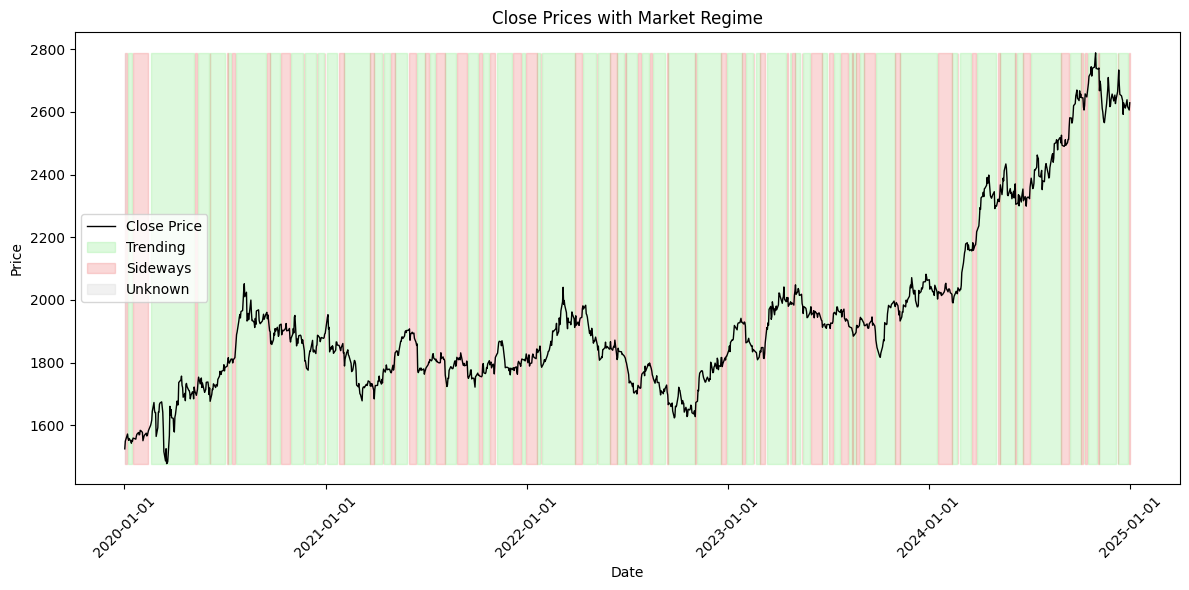

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import colors

def plot_price_regime(df, price_col='Close', regime_col='regime'):
    """
    Plot closing prices with market regime as background color.

    Parameters:
    - df: DataFrame with columns for prices, regime labels, and datetime index.
    - price_col: Column name for closing prices.
    - regime_col: Column name for regime labels ('oscillating', 'trending', 'unknown').
    """
    # Ensure index is datetime
    df.index = pd.to_datetime(df.index)

    # Create figure and axis
    fig, ax = plt.subplots(figsize=(12, 6))

    # Plot closing prices
    ax.plot(df.index, df[price_col], label='Close Price', color='black', linewidth=1)


    # Map regimes to colors
    regime_colors = {'trending': 'lightgreen', 'sideways': 'lightcoral', 'unknown': 'lightgrey'}
    regime_numeric = df[regime_col].map({'trending': 1, 'sideways': 2, 'unknown': 0})

    # Create background colors for regimes
    for regime, color in regime_colors.items():
        mask = df[regime_col] == regime
        ax.fill_between(df.index, df[price_col].min(), df[price_col].max(),
                        where=mask, color=color, alpha=0.3, label=regime.capitalize())

    # Customize plot
    ax.set_title('Close Prices with Market Regime')
    ax.set_xlabel('Date')
    ax.set_ylabel('Price')
    ax.legend()

    # Format x-axis dates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    plt.xticks(rotation=45)

    # Tight layout and show plot
    plt.tight_layout()
    plt.show()

# Example usage:
# Assume 'df' has 'close' and 'regime' columns from label_market_regime
# df['regime'] = label_market_regime(df['close'])
plot_price_regime(df)

In [62]:
df['ret'] = df['Close'].pct_change()
df.drop(df.index[0:6], inplace=True)
df

Price,Close,High,Low,Open,Volume,ma5,regime,ret
Date,,,,,,,,
2020-01-10,1557.500000,1558.800049,1545.400024,1551.199951,16,1554.599976,trending,0.003738
2020-01-13,1548.400024,1558.000000,1548.400024,1557.400024,48,1552.950012,trending,-0.005843
2020-01-14,1542.400024,1546.699951,1534.900024,1546.699951,32,1545.400024,trending,-0.003875
2020-01-15,1552.099976,1553.900024,1545.599976,1548.000000,11,1547.250000,trending,0.006289
2020-01-16,1549.000000,1556.099976,1548.500000,1555.699951,98,1550.549988,trending,-0.001997
...,...,...,...,...,...,...,...,...
2024-12-24,2620.000000,2620.000000,2609.500000,2613.000000,35,2616.150024,trending,0.002948
2024-12-26,2638.800049,2638.800049,2627.899902,2628.500000,84,2629.400024,trending,0.007176
2024-12-27,2617.199951,2617.699951,2616.399902,2617.699951,642,2628.000000,trending,-0.008186


In [63]:

# Assuming df is your DataFrame with the provided structure
# df = pd.read_csv(...) or similar to load your data

# Ensure the DataFrame has the correct columns and is sorted by date
df = df.sort_index()



# 1. Simple Moving Average (SMA) of returns (5-period)
df['SMA_ret_5'] = talib.SMA(df['ret'], timeperiod=5)

# 2. Exponential Moving Average (EMA) of returns (5-period)
df['EMA_ret_5'] = talib.EMA(df['ret'], timeperiod=5)

# 3. Standard Deviation (STD) of returns (5-period)
df['STD_ret_5'] = talib.STDDEV(df['ret'], timeperiod=5, nbdev=1)

# 4. Relative Strength Index (RSI) adapted for returns (14-period)
# RSI typically uses price data, but we can compute it on returns
df['RSI_ret_14'] = talib.RSI(df['ret'], timeperiod=14)

# 5. Average True Range (ATR) (14-period, using High, Low, Close)
df['ATR_14'] = talib.ATR(df['High'], df['Low'], df['Close'], timeperiod=14)

# 6. Average Directional Index (ADX) (14-period, using High, Low, Close)
df['ADX_14'] = talib.ADX(df['High'], df['Low'], df['Close'], timeperiod=14)

# 7. Commodity Channel Index (CCI) (14-period, using High, Low, Close)
df['CCI_14'] = talib.CCI(df['High'], df['Low'], df['Close'], timeperiod=14)

# 8. Rate of Change (ROC) of returns (5-period)
df['ROC_ret_5'] = talib.ROC(df['ret'], timeperiod=5)

# 9. Bollinger Bands Width (based on returns, 20-period SMA, 2 STD)
upper_band, middle_band, lower_band = talib.BBANDS(df['ret'], timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)
df['BB_Width_20'] = (upper_band - lower_band) / middle_band

# 10. Momentum of returns (5-period)
df['Momentum_ret_5'] = talib.MOM(df['ret'], timeperiod=5)

df

Price,Close,High,Low,Open,Volume,ma5,regime,ret,SMA_ret_5,EMA_ret_5,STD_ret_5,RSI_ret_14,ATR_14,ADX_14,CCI_14,ROC_ret_5,BB_Width_20,Momentum_ret_5
Date,,,,,,,,,,,,,,,,,,
2020-01-10,1557.500000,1558.800049,1545.400024,1551.199951,16,1554.599976,trending,0.003738,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-13,1548.400024,1558.000000,1548.400024,1557.400024,48,1552.950012,trending,-0.005843,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-14,1542.400024,1546.699951,1534.900024,1546.699951,32,1545.400024,trending,-0.003875,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-15,1552.099976,1553.900024,1545.599976,1548.000000,11,1547.250000,trending,0.006289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-16,1549.000000,1556.099976,1548.500000,1555.699951,98,1550.549988,trending,-0.001997,-0.000338,-0.000338,0.004606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,2620.000000,2620.000000,2609.500000,2613.000000,35,2616.150024,trending,0.002948,-0.001800,-0.000565,0.010207,51.160414,32.618832,13.482915,-74.748432,-211.645728,356.074353,0.005588
2024-12-26,2638.800049,2638.800049,2627.899902,2628.500000,84,2629.400024,trending,0.007176,0.000232,0.002015,0.010765,52.442111,31.631776,12.555195,-29.737530,-340.194520,94.949721,0.010163
2024-12-27,2617.199951,2617.699951,2616.399902,2617.699951,642,2628.000000,trending,-0.008186,0.001956,-0.001385,0.008310,47.558777,30.972374,12.040787,-67.976104,-51.283868,-97.458218,0.008617


In [64]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from io import StringIO  # For parsing sample data; replace with your full data loading method

df['regime_future'] = df['regime'].shift(-1)
df.dropna(inplace=True)



# Define features and target
features = ['ret', 'SMA_ret_5', 'EMA_ret_5', 'STD_ret_5', 'RSI_ret_14', 'ATR_14', 'ADX_14', 'CCI_14', 'ROC_ret_5', 'BB_Width_20', 'Momentum_ret_5']
target = 'regime_future'

# Drop rows with NaN in features or target (common in early data due to indicator windows)
df = df[features + [target]].dropna()

# Encode the target (binary classification)
le = LabelEncoder()
df[target] = le.fit_transform(df[target])  # 'sideways' -> 0, 'trending' -> 1

# Split data into X (features) and y (target)
X = df[features]
y = df[target]

# Split into train/test sets (80/20; use time-based split for financial data in production, e.g., earlier dates for train)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Train the Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Step 3: Evaluate the model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Feature importances (to see which indicators contribute most)
importances = pd.DataFrame({'Feature': features, 'Importance': model.feature_importances_}).sort_values('Importance', ascending=False)
print("Feature Importances:\n", importances)

# Example: Predict on new data (e.g., a hypothetical future row as of 2025-09-30)
# Replace with actual values
new_data = pd.DataFrame({
    'ret': [0.005],
    'SMA_ret_5': [0.002],
    'EMA_ret_5': [0.0015],
    'STD_ret_5': [0.008],
    'RSI_ret_14': [55.0],
    'ATR_14': [25.0],
    'ADX_14': [20.0],
    'CCI_14': [-50.0],
    'ROC_ret_5': [-100.0],
    'BB_Width_20': [0.01],
    'Momentum_ret_5': [0.007]
})
predicted_regime = le.inverse_transform(model.predict(new_data))
print(f"Predicted regime for new data: {predicted_regime[0]}")

Accuracy: 0.80
Classification Report:
               precision    recall  f1-score   support

    sideways       0.77      0.52      0.62        77
    trending       0.81      0.93      0.86       168

    accuracy                           0.80       245
   macro avg       0.79      0.72      0.74       245
weighted avg       0.80      0.80      0.79       245

Confusion Matrix:
 [[ 40  37]
 [ 12 156]]
Feature Importances:
            Feature  Importance
1        SMA_ret_5    0.151205
2        EMA_ret_5    0.117501
3        STD_ret_5    0.115208
7           CCI_14    0.114710
5           ATR_14    0.104959
6           ADX_14    0.096743
9      BB_Width_20    0.070022
10  Momentum_ret_5    0.067309
0              ret    0.055944
4       RSI_ret_14    0.054375
8        ROC_ret_5    0.052024
Predicted regime for new data: trending


In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Sample data (replace with your actual DataFrame)
data = {
    'Date': ['2020-01-10', '2020-01-13', '2020-01-14', '2020-01-15', '2020-01-16', '2024-12-24', '2024-12-26', '2024-12-27'],
    'Close': [1558.800049, 1558.000000, 1546.699951, 1553.900024, 1556.099976, 2620.000000, 2638.800049, 2617.699951],
    'regime': ['trending', 'trending', 'trending', 'trending', 'trending', 'trending', 'trending', 'trending']
}
df = pd.DataFrame(data)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

# Create new DataFrame with 'Close' and 'regime'
df_new = df[['Close', 'regime']].copy()

# Compute daily returns
df_new['ret'] = df_new['Close'].pct_change()

# Compute indicators
df_new['MA20'] = df_new['Close'].rolling(window=20).mean()
df_new['MA50'] = df_new['Close'].rolling(window=50).mean()
df_new['std20'] = df_new['Close'].rolling(window=20).std()
df_new['upper_bb'] = df_new['MA20'] + 2 * df_new['std20']
df_new['lower_bb'] = df_new['MA20'] - 2 * df_new['std20']
# df_new = df_new.dropna()
print(df_new.head())
# # MA strategy: long (1) when MA20 > MA50, short (-1) when MA20 < MA50
# df_new['ma_signal'] = np.where(df_new['MA20'] > df_new['MA50'], 1,
#                                np.where(df_new['MA20'] < df_new['MA50'], -1, 0))

# # BB strategy: short when price > upper BB until price <= lower BB, long when price < lower BB until price >= upper BB
# df_new['bb_signal'] = 0
# position = 0  # 0: neutral, 1: long, -1: short
# for i in range(1, len(df_new)):
#     if df_new['Close'].iloc[i] > df_new['upper_bb'].iloc[i] and position != -1:
#         position = -1
#     elif df_new['Close'].iloc[i] < df_new['lower_bb'].iloc[i] and position != 1:
#         position = 1
#     elif position == -1 and df_new['Close'].iloc[i] <= df_new['lower_bb'].iloc[i]:
#         position = 0
#     elif position == 1 and df_new['Close'].iloc[i] >= df_new['upper_bb'].iloc[i]:
#         position = 0
#     df_new['bb_signal'].iloc[i] = position

# # Combined strategy: MA signal when trending, BB signal when sideway
# df_new['signal'] = np.where(df_new['regime'] == 'trending', df_new['ma_signal'], df_new['bb_signal'])

# # Set signals to 0 where indicators are NaN
# df_new['signal'] = np.where(df_new['MA50'].isna() | df_new['std20'].isna(), 0, df_new['signal'])

# # Compute returns
# df_new['ma_ret'] = df_new['ma_signal'].shift(1) * df_new['ret']
# df_new['bb_ret'] = df_new['bb_signal'].shift(1) * df_new['ret']
# df_new['strat_ret'] = df_new['signal'].shift(1) * df_new['ret']

# # Drop NaN rows for backtest
# df_backtest = df_new.dropna(subset=['strat_ret'])

# # Compute cumulative returns
# df_backtest['cum_ma'] = (1 + df_backtest['ma_ret']).cumprod()
# df_backtest['cum_bb'] = (1 + df_backtest['bb_ret']).cumprod()
# df_backtest['cum_strat'] = (1 + df_backtest['strat_ret']).cumprod()
# df_backtest['cum_market'] = (1 + df_backtest['ret']).cumprod()

# # Print results
# if not df_backtest.empty:
#     print(f"MA Strategy Return: {(df_backtest['cum_ma'].iloc[-1] - 1):.2%}")
#     print(f"BB Strategy Return: {(df_backtest['cum_bb'].iloc[-1] - 1):.2%}")
#     print(f"Combined Strategy Return: {(df_backtest['cum_strat'].iloc[-1] - 1):.2%}")
#     print(f"Market Return: {(df_backtest['cum_market'].iloc[-1] - 1):.2%}")
# else:
#     print("No valid data for backtest after dropping NaNs.")

# # Plot cumulative returns
# plt.figure(figsize=(10, 6))
# plt.plot(df_backtest.index, df_backtest['cum_ma'], label='MA Strategy')
# plt.plot(df_backtest.index, df_backtest['cum_bb'], label='BB Strategy')
# plt.plot(df_backtest.index, df_backtest['cum_strat'], label='Combined Strategy')
# plt.plot(df_backtest.index, df_backtest['cum_market'], label='Market')
# plt.title('Strategy vs. Market Cumulative Returns')
# plt.ylabel('Cumulative Return')
# plt.xlabel('Date')
# plt.legend()
# plt.grid(True)
# plt.show()

                  Close    regime       ret  MA20  MA50  std20  upper_bb  \
Date                                                                       
2020-01-10  1558.800049  trending       NaN   NaN   NaN    NaN       NaN   
2020-01-13  1558.000000  trending -0.000513   NaN   NaN    NaN       NaN   
2020-01-14  1546.699951  trending -0.007253   NaN   NaN    NaN       NaN   
2020-01-15  1553.900024  trending  0.004655   NaN   NaN    NaN       NaN   
2020-01-16  1556.099976  trending  0.001416   NaN   NaN    NaN       NaN   

            lower_bb  
Date                  
2020-01-10       NaN  
2020-01-13       NaN  
2020-01-14       NaN  
2020-01-15       NaN  
2020-01-16       NaN  
